# 247. Does a panel of BCL-2 family queries from distant animals find human BCL2 better than CED-9 alone?

**Idea.** Search human Swiss-Prot with several BCL-2 family proteins from animals that
are not chordates, one at a time. The hypothesis is that the different query sequences will give different chance hits.
Shared composition or low-complexity stretches could instead give repeated chance hits. The true target (human BCL2) and the
place it is hit (the BH1 block) should repeat across queries. Counting how many queries
hit each human protein should then lift BCL2 above chance. This is not the
alphabet-combining idea of
[PR 48](https://github.com/seanome/2024-kmerseek-analysis/pull/48) (notebook 242), which
reported repeated long-protein hits across alphabets. Here the queries differ and
the alphabet stays fixed.

**Decision.** Keep or drop "many distant queries, one alphabet" as the way to reach
twilight-zone homologs such as BCL2 from CED-9. If prediction 1 fails, the idea is
dropped and this notebook says so. No other setting is tried to rescue it.

**Predictions, written before any search was run:**

1. BCL2's panel score will be above the 95th percentile of the scores of 100 shuffled
   panels. (Panel score of a human protein = the number of panel queries that hit it,
   ties broken by the sum of -ln(region E-value) over those queries. Higher is better.)
2. Most queries that hit BCL2 will land on or overlap BCL2 residues 139-157, the BH1
   block that CED-9 residues 163-181 match at hp_lehninger2, k = 17.
3. Once the real BCL-2 family targets are removed, the queries' sets of hit targets will
   overlap each other with a median pairwise Jaccard index below 0.3. (Jaccard index =
   shared targets / targets hit by either query; 0 means no shared targets, 1 means the
   same targets. Lower is better for this idea.)

**Fixed kmerseek setting, for every search:** alphabet hp_lehninger2 (two letters:
hydrophobic AFGILMPVWY, polar CDEHKNQRST), k = 17, scaled 1, no extension,
low-complexity mask on. Each query is searched on its own against a human Swiss-Prot
index. The proposed ranking used `region_evalue`, but an exact, unfitted search can return only
infinite E-values. This is a second unresolved precondition: a future plan must first
specify a ranking with valid measured values. No search or performance test was run.

**Queries.** 5 to 8 BCL-2 family proteins from animals that are not chordates: C. elegans
CED-9, Drosophila Buffy and Debcl, at least one cnidarian, and any other non-chordate
animal Swiss-Prot has. They are found by Pfam family (PF00452 Bcl-2, PF02180 BH4) in the
Swiss-Prot flat file, not by typed accessions. With fewer than 5, the notebook stops.

In [1]:
import gzip
from pathlib import Path

import polars as pl

pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(120)

#: Swiss-Prot flat file and the FASTA from the same download (2025-07-03).
SPROT_DAT = Path("/Users/olga/data/uniprot/uniprot_sprot.dat.gz")
SPROT_FASTA = Path("/Users/olga/data/uniprot/uniprot_sprot.fasta.gz")
#: A later Swiss-Prot release (2026_03), used only to check nothing new was added.
SPROT_FASTA_2026_03 = Path("/Users/olga/data/uniprot/uniprot_sprot.2026_03.fasta.gz")
#: Written by scripts/bcl2_family_from_swissprot.py from SPROT_DAT.
FAMILY_TSV = Path("../tables/247_swissprot_bcl2_family_PF00452_PF02180.tsv")
MIN_QUERIES = 5

family = pl.read_csv(FAMILY_TSV, separator="\t")
family = family.with_columns(
    pl.when(pl.col("lineage").str.starts_with("Viruses"))
    .then(pl.lit("virus"))
    .when(pl.col("lineage").str.contains("Chordata"))
    .then(pl.lit("chordate"))
    .when(pl.col("lineage").str.contains("Metazoa"))
    .then(pl.lit("non-chordate animal"))
    .otherwise(pl.lit("other"))
    .alias("group")
)
print("Swiss-Prot entries with PF00452 or PF02180, by group:")
print(family.group_by("group").agg(pl.len().alias("n_entries")).sort("group"))
candidates = family.filter(pl.col("group") == "non-chordate animal")
print(f"\nNon-chordate animal candidates: {candidates.height}")
print(
    candidates.select("accession", "entry_name", "species", "taxid", "pfam", "length")
)

Swiss-Prot entries with PF00452 or PF02180, by group:
shape: (3, 2)
┌─────────────────────┬───────────┐
│ group               ┆ n_entries │
│ ---                 ┆ ---       │
│ str                 ┆ u32       │
╞═════════════════════╪═══════════╡
│ chordate            ┆ 45        │
│ non-chordate animal ┆ 2         │
│ virus               ┆ 12        │
└─────────────────────┴───────────┘

Non-chordate animal candidates: 2
shape: (2, 6)
┌───────────┬────────────┬─────────────────────────┬───────┬─────────────────┬────────┐
│ accession ┆ entry_name ┆ species                 ┆ taxid ┆ pfam            ┆ length │
│ ---       ┆ ---        ┆ ---                     ┆ ---   ┆ ---             ┆ ---    │
│ str       ┆ str        ┆ str                     ┆ i64   ┆ str             ┆ i64    │
╞═══════════╪════════════╪═════════════════════════╪═══════╪═════════════════╪════════╡
│ P41957    ┆ CED9_CAEBR ┆ Caenorhabditis briggsae ┆ 6238  ┆ PF00452,PF02180 ┆ 266    │
│ P41958    ┆ CED9_CAEEL ┆ Caen

In [2]:
def fasta_headers(path, accessions):
    """Full FASTA header line for each accession in a UniProt FASTA."""
    out = {}
    with gzip.open(path, "rt") as fh:
        for line in fh:
            if line.startswith(">") and line.split("|")[1] in accessions:
                out[line.split("|")[1]] = line.rstrip()
    return out


headers = fasta_headers(SPROT_FASTA, set(candidates["accession"]))
print("Full FASTA headers of the candidates (Swiss-Prot, 2025-07-03 download):")
for acc in candidates["accession"]:
    print(headers[acc])

Full FASTA headers of the candidates (Swiss-Prot, 2025-07-03 download):
>sp|P41957|CED9_CAEBR Apoptosis regulator ced-9 OS=Caenorhabditis briggsae OX=6238 GN=ced-9 PE=3 SV=2
>sp|P41958|CED9_CAEEL Apoptosis regulator ced-9 OS=Caenorhabditis elegans OX=6239 GN=ced-9 PE=1 SV=1


## Are Buffy, Debcl or a cnidarian protein in a newer Swiss-Prot?

The flat file is from July 2025. The check below reads every header of Swiss-Prot
release 2026_03 for Drosophila melanogaster (taxon 7227), Hydra vulgaris (6087),
Nematostella vectensis (45351), Trichoplax adhaerens (10228) and Amphimedon queenslandica
(400682), and keeps those whose description names Bcl-2, Buffy, Debcl or "apoptosis
regulator". A missing name match does not establish absence of a family member.

In [3]:
import re

#: Non-chordate animals where a BCL-2 family protein is known to exist.
CHECK_TAXA = {
    "7227": "Drosophila melanogaster",
    "6087": "Hydra vulgaris",
    "45351": "Nematostella vectensis",
    "10228": "Trichoplax adhaerens",
    "400682": "Amphimedon queenslandica",
}
name_hit = re.compile(r"bcl-2|buffy|debcl|apoptosis regulator", re.I)
rows = []
with gzip.open(SPROT_FASTA_2026_03, "rt") as fh:
    for line in fh:
        if not line.startswith(">"):
            continue
        ox = re.search(r" OX=(\d+) ", line).group(1)
        if ox in CHECK_TAXA:
            rows.append(
                {
                    "taxid": ox,
                    "species": CHECK_TAXA[ox],
                    "bcl2_like_name": bool(name_hit.search(line)),
                }
            )
check = (
    pl.DataFrame(rows)
    .group_by("taxid", "species")
    .agg(
        pl.len().alias("n_swissprot_entries"),
        pl.col("bcl2_like_name").sum().alias("n_bcl2_like_names"),
    )
    .sort("species")
)
print(check)

shape: (5, 4)
┌────────┬──────────────────────────┬─────────────────────┬───────────────────┐
│ taxid  ┆ species                  ┆ n_swissprot_entries ┆ n_bcl2_like_names │
│ ---    ┆ ---                      ┆ ---                 ┆ ---               │
│ str    ┆ str                      ┆ u32                 ┆ u32               │
╞════════╪══════════════════════════╪═════════════════════╪═══════════════════╡
│ 400682 ┆ Amphimedon queenslandica ┆ 2                   ┆ 0                 │
│ 7227   ┆ Drosophila melanogaster  ┆ 3904                ┆ 0                 │
│ 6087   ┆ Hydra vulgaris           ┆ 57                  ┆ 0                 │
│ 45351  ┆ Nematostella vectensis   ┆ 144                 ┆ 0                 │
│ 10228  ┆ Trichoplax adhaerens     ┆ 23                  ┆ 0                 │
└────────┴──────────────────────────┴─────────────────────┴───────────────────┘


(162794, 42908)

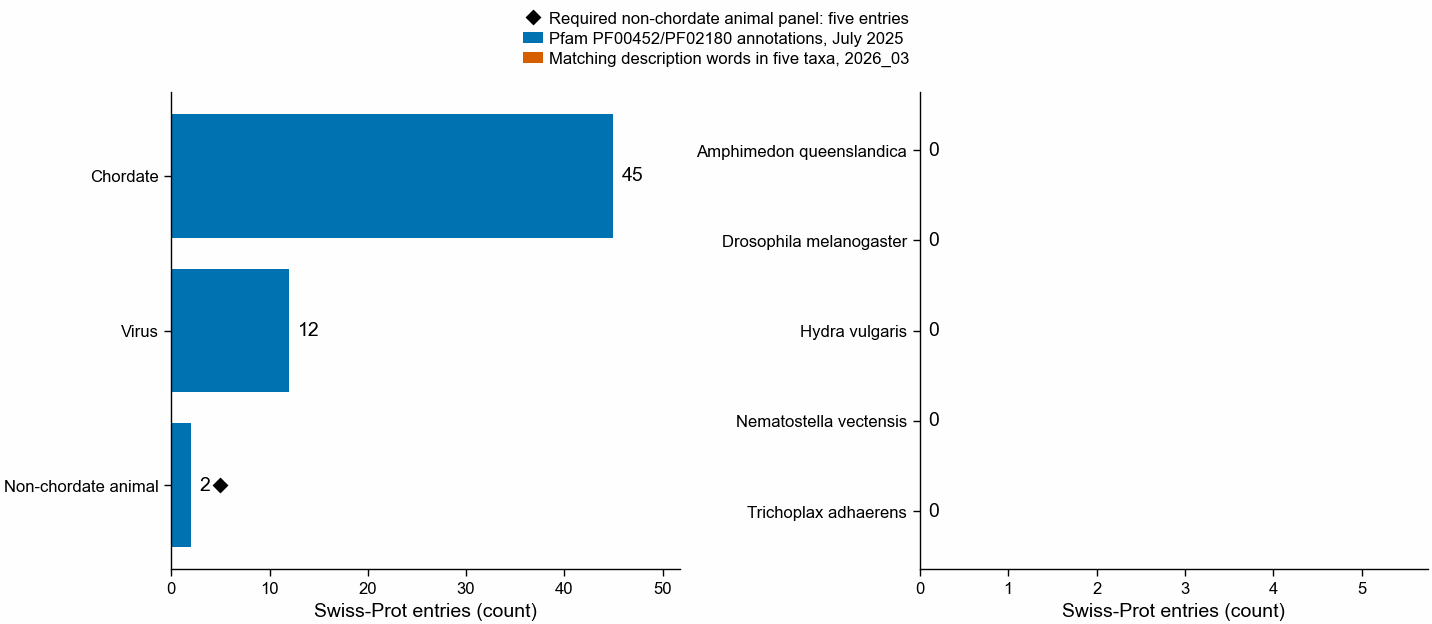

In [4]:
import matplotlib.pyplot as plt
import pubfig as pf

pf.use_style()
group_counts = dict(family.group_by("group").agg(pl.len()).iter_rows())
fig, axes = pf.figure(pf.TWO_COLUMN_MM, 80, ncols=2)
for ax, labels, counts, color, key in [
    (
        axes[0],
        ["Chordate", "Virus", "Non-chordate animal"],
        [group_counts.get(g, 0) for g in ["chordate", "virus", "non-chordate animal"]],
        pf.OKABE_ITO["blue"],
        "Pfam PF00452/PF02180 annotations, July 2025",
    ),
    (
        axes[1],
        check["species"].to_list(),
        check["n_bcl2_like_names"].to_list(),
        pf.OKABE_ITO["vermillion"],
        "Matching description words in five taxa, 2026_03",
    ),
]:
    y = list(range(len(labels)))[::-1]
    ax.barh(y, counts, color=color, label=key)
    for yi, count in zip(y, counts):
        ax.annotate(
            str(count),
            (count, yi),
            xytext=(3, 0),
            textcoords="offset points",
            va="center",
        )
    ax.set_yticks(y, labels)
    ax.set_xlim(0, max(max(counts), MIN_QUERIES) * 1.15)
    ax.set_xlabel("Swiss-Prot entries (count)")
axes[0].plot(
    MIN_QUERIES,
    0,
    marker="D",
    color="black",
    linestyle="",
    label="Required non-chordate animal panel: five entries",
)
pf.shared_legend(fig, ncol=1)
pf.save(fig, "../figures/247_swissprot_bcl2_family_entries_by_group")
# Reuse the repo PNG export check for this flat-colour chart.
import sys

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from shrink_png import process

process(Path("../figures/247_swissprot_bcl2_family_entries_by_group.png"), check=False)

In [5]:
n = candidates.height
if n < MIN_QUERIES:
    print(
        f"STOP: Swiss-Prot has {n} BCL-2 family proteins from non-chordate animals "
        f"({', '.join(candidates['entry_name'])}); the panel needs at least {MIN_QUERIES}. "
        "No search was run."
    )

STOP: Swiss-Prot has 2 BCL-2 family proteins from non-chordate animals (CED9_CAEBR, CED9_CAEEL); the panel needs at least 5. No search was run.


## Status

Stopped before any search. The July 2025 Swiss-Prot flat file has two entries annotated
with PF00452 or PF02180 from animals that are not chordates, CED-9 of *C. elegans* (P41958) and of *C. briggsae* (P41957),
and the panel needs at least 5. The July annotation filter does not recover Buffy, Debcl or a cnidarian candidate.
The separate 2026_03 check finds no matching description words in the five selected taxa.
It does not search all cnidarians or test proteins lacking those description words. The other 12 non-chordate
entries with PF00452 are from viruses, not animals. The panel needs a suitable query source and a valid ranking plan. The proposed
E-value ranking was not tested; infinite values from an unfitted exact search cannot
provide the proposed finite ranking. No sensitivity result follows from this stopped plan.